# 01 · Data dan Eksplorasi

Data jumlah penumpang kereta api bulanan, Januari 2016 sampai Desember 2023 (96 bulan).

**Pembagian data**
- Data latih: Januari 2016 sampai Desember 2022 (84 bulan)
- Data uji: Januari sampai Desember 2023 (12 bulan), **hanya dipakai sekali di akhir** untuk menilai model

Notebook ini memeriksa kualitas data sebelum pemodelan, karena tiga hal di data ini memengaruhi cara hasil model harus dibaca.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.forecasting import *

quiet()
setup_plot()
pd.options.display.float_format = '{:,.2f}'.format

In [2]:
y = load_passengers()
print(f"{len(y)} bulan: {y.index[0]:%b %Y} sampai {y.index[-1]:%b %Y}")
y.describe()

96 bulan: Jan 2016 sampai Dec 2023


count          96.00
mean      807,128.03
std       340,758.57
min        66,523.00
25%       632,783.23
50%       819,458.81
75%     1,042,912.96
max     1,487,349.00
Name: penumpang, dtype: float64

## 1. Data 2016–2018 adalah hasil interpolasi, bukan observasi

Untuk 2016–2018 hanya tersedia **total tahunan**. Data bulanannya dibuat dengan membagi total tahunan memakai proporsi tiap bulan di tahun 2019.

Konsekuensinya: pola musiman 2016, 2017, dan 2018 **identik** dengan 2019. Sel di bawah membuktikannya: persentase penumpang per bulan terhadap total tahunan sama persis di keempat tahun itu.

In [3]:
share = y.groupby(y.index.year).transform(lambda s: s / s.sum() * 100)  # persen
share_tbl = share['2016':'2019'].groupby(share['2016':'2019'].index.year).apply(lambda s: s.round(2).tolist())
share_tbl = pd.DataFrame(share_tbl.tolist(), index=share_tbl.index,
                         columns=pd.date_range('2019-01', periods=12, freq='MS').strftime('%b'))
share_tbl

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
date,,,,,,,,,,,,
2016,7.90,7.40,8.34,8.69,7.23,9.42,9.16,8.46,7.42,7.85,8.17,9.96
2017,7.90,7.40,8.34,8.69,7.23,9.42,9.16,8.46,7.42,7.85,8.17,9.96
2018,7.90,7.40,8.34,8.69,7.23,9.42,9.16,8.46,7.42,7.85,8.17,9.96
2019,7.90,7.40,8.34,8.69,7.23,9.42,9.16,8.46,7.42,7.85,8.17,9.96


In [4]:
annual = y['2016':'2018'].groupby(y['2016':'2018'].index.year).sum().round()
annual  # total tahunan asli: 8.532.295 · 8.663.509 · 11.378.027

date
2016    8,532,295.00
2017    8,663,509.00
2018   11,378,027.00
Name: penumpang, dtype: float64

Artinya 36 dari 84 bulan data latih (43%) memiliki pola musiman buatan. Model musiman seperti SARIMA dan Prophet akan "melihat" pola musim yang sangat rapi, sehingga tingkat keyakinan terhadap komponen musimannya terlalu tinggi.

## 2. Pandemi COVID-19 memotong seri waktu

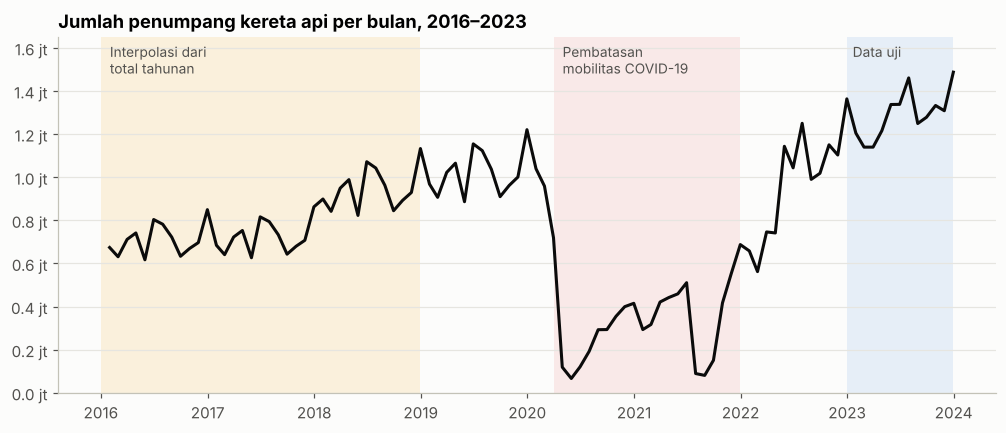

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axvspan(pd.Timestamp('2016-01-01'), pd.Timestamp('2018-12-31'), color='#eda100', alpha=0.12, lw=0)
ax.axvspan(pd.Timestamp('2020-04-01'), pd.Timestamp('2021-12-31'), color='#e34948', alpha=0.10, lw=0)
ax.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-31'), color='#2a78d6', alpha=0.10, lw=0)
ax.plot(y.index, y.values, color=COLORS['Aktual'])
for x, label in [('2016-02-01', 'Interpolasi dari\ntotal tahunan'),
                 ('2020-05-01', 'Pembatasan\nmobilitas COVID-19'),
                 ('2023-01-20', 'Data uji')]:
    ax.text(pd.Timestamp(x), 1.62e6, label, va='top', fontsize=9, color='#52514e')
ax.set_ylim(0, 1.65e6)
million_axis(ax)
ax.set_title('Jumlah penumpang kereta api per bulan, 2016–2023')
fig.savefig('../images/01_seri_waktu.png')
plt.show()

Penumpang turun sekitar 94% dari Januari ke Mei 2020, lalu jatuh lagi saat PPKM Juli–Agustus 2021. Tanpa penanganan, model akan menganggap penurunan ini sebagai bagian dari tren atau musim. Karena itu semua model memakai variabel dummy `covid` (April 2020 sampai Desember 2021).

## 3. Februari dan Maret 2023 bernilai persis sama

In [6]:
dup = y[y.duplicated(keep=False)]
dup

date
2023-02-28   1,139,583.00
2023-03-31   1,139,583.00
Freq: ME, Name: penumpang, dtype: float64

Dua bulan berturut-turut dengan angka identik sampai satuan hampir pasti kesalahan input saat pengumpulan data. Nilai asli Maret 2023 tidak diketahui, jadi data **tidak diubah**. Notebook 04 menghitung ulang metrik tanpa bulan Maret sebagai uji sensitivitas.

## 4. Fitur eksternal (variabel eksogen)

| Fitur | Isi | Kenapa |
|---|---|---|
| `covid` | 1 untuk April 2020 – Desember 2021 | menandai periode pembatasan mobilitas |
| `lebaran` | 1 untuk bulan Idulfitri | puncak arus mudik, bulannya bergeser tiap tahun karena kalender Hijriah |
| `jumlah_libur` | banyaknya hari libur nasional + cuti bersama dalam sebulan | intensitas libur |

**Catatan perbaikan dari versi skripsi:** di skripsi, fitur libur dibuat dengan mencocokkan *tanggal akhir bulan* (misalnya 31 Januari) dengan daftar tanggal libur harian. Hasilnya hampir selalu 0, karena hanya bulan yang libur tepat di tanggal terakhirnya yang bernilai 1:

In [7]:
h = load_holidays()
old_feature = pd.Series(y.index.isin(h['tanggal']).astype(int), index=y.index)
print('Bulan bernilai 1 pada fitur is_holiday versi skripsi:')
print(old_feature[old_feature == 1].index.strftime('%Y-%m').tolist())

Bulan bernilai 1 pada fitur is_holiday versi skripsi:
['2017-06', '2020-07', '2020-12', '2022-02', '2023-06']


In [8]:
X = make_exog(y.index)
X.loc['2023']

,jumlah_libur,lebaran,covid
date,,,
2023-01-31,3,0,0
2023-02-28,1,0,0
2023-03-31,2,0,0
2023-04-30,8,1,0
2023-05-31,2,0,0
2023-06-30,6,0,0
2023-07-31,1,0,0
2023-08-31,1,0,0
2023-09-30,1,0,0


Lebaran maju sekitar 11 hari per tahun, sehingga bulan puncaknya bergeser: Juni pada 2017–2019, Mei pada 2020–2022, dan April pada 2023. Pola musiman 12 bulan yang tetap (seperti di SARIMA biasa) tidak bisa menangkap pergeseran ini, karena itu Lebaran dijadikan variabel tersendiri.

In [9]:
X.to_csv('../data/processed/fitur_eksogen.csv', index_label='bulan')
y.to_frame().to_csv('../data/processed/penumpang_bulanan.csv', index_label='bulan')